# BÁO CÁO BÀI TẬP LAB 02
## Assignment 1: Logistic Regression bằng NumPy
- **Họ và tên:** Nguyễn Văn Phát
- **MSSV:** 24521314
- **Môn học:** Học máy Thống kê (DS102)

## 1. Chuẩn bị dữ liệu

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

features = ['Age', 'Weight_kg', 'Sex', 'Num_Drugs']
target = 'Hospitalization'

X_train = train[features].values
y_train = train[target].values
X_test = test[features].values
y_test = test[target].values

# Chuan hoa du lieu
mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)
X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

print("Kích thước tập train:", X_train.shape, y_train.shape)
print("Kích thước tập test:", X_test.shape, y_test.shape)

Kích thước tập train: (7920, 4) (7920,)
Kích thước tập test: (1981, 4) (1981,)


## 2. Cài đặt mô hình Logistic Regression

In [2]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

class LogisticRegression:
    def __init__(self, lr=0.1, epochs=1000):
        self.lr = lr
        self.epochs = epochs
        self.W = None
        self.b = 0.0
        self.losses = []

    def fit(self, X, y):
        n, d = X.shape
        self.W = np.zeros(d)
        self.b = 0.0
        self.losses = []

        for i in range(self.epochs):
            z = np.dot(X, self.W) + self.b
            y_hat = sigmoid(z)

            # Tinh loss BCE
            loss = -np.mean(y * np.log(y_hat + 1e-9) + (1 - y) * np.log(1 - y_hat + 1e-9))
            self.losses.append(loss)

            # Gradient descent
            dz = y_hat - y
            dW = np.dot(X.T, dz) / n
            db = np.sum(dz) / n

            self.W -= self.lr * dW
            self.b -= self.lr * db

            if (i + 1) % 200 == 0:
                print(f"Epoch {i + 1}: Loss = {loss:.4f}")

    def predict(self, X):
        z = np.dot(X, self.W) + self.b
        return (sigmoid(z) >= 0.5).astype(int)

## 3. Huấn luyện và trực quan hóa hàm mất mát

Epoch 200: Loss = 0.6129
Epoch 400: Loss = 0.6129
Epoch 600: Loss = 0.6129
Epoch 800: Loss = 0.6129
Epoch 1000: Loss = 0.6129


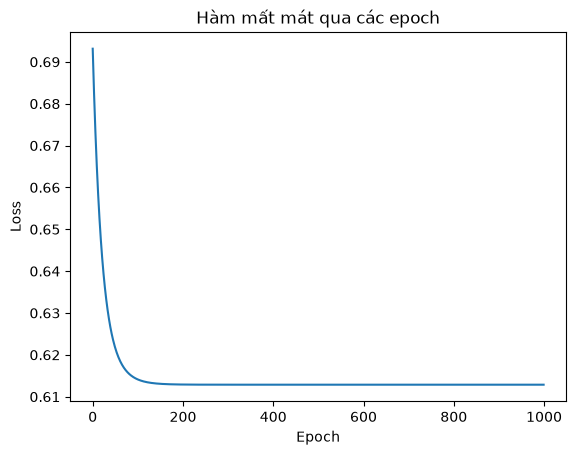

In [3]:
model = LogisticRegression(lr=0.1, epochs=1000)
model.fit(X_train, y_train)

# Ve bieu do loss
plt.plot(model.losses)
plt.title("Hàm mất mát qua các epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

## 4. Đánh giá mô hình trên tập test

In [4]:
y_pred = model.predict(X_test)

tp = np.sum((y_pred == 1) & (y_test == 1))
fp = np.sum((y_pred == 1) & (y_test == 0))
fn = np.sum((y_pred == 0) & (y_test == 1))

precision = tp / (tp + fp)
recall = tp / (tp + fn)
f1 = 2 * precision * recall / (precision + recall)

print("--- Kết quả đánh giá ---")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")

--- Kết quả đánh giá ---
Precision: 0.6000
Recall:    0.1140
F1-score:  0.1916
